# Health Index và dự báo ARIMA trên FD001 train

Học viên: Phan Nguyễn Mai Phương — MSHV 25002711

Đây là một phân tích chuỗi thời gian phụ, tách khỏi mô hình RUL. Tôi gom các sensor thành
một chỉ số sức khỏe duy nhất (Health Index), rồi xem ARIMA dự báo chỉ số này tốt đến đâu so
với hai cách dự báo ngây thơ. Kết quả đọc từ `outputs/timeseries/`, notebook không fit lại
ARIMA.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent  # khi mở notebook từ thư mục notebooks/

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_json(path):
    return json.loads((ROOT / path).read_text(encoding="utf-8"))


from scipy.stats import spearmanr

from cmapss.timeseries.baselines import evaluate_forecast_baselines

%matplotlib inline

TS = ROOT / "outputs" / "timeseries"
health_index = pd.read_csv(TS / "tables" / "health_index.csv")
forecast_metrics = pd.read_csv(TS / "tables" / "forecast_metrics.csv")
diagnostics = pd.read_csv(TS / "tables" / "diagnostics.csv")
forecasts = pd.read_parquet(TS / "predictions" / "arima_forecasts.parquet")

print("Số dòng Health Index:", len(health_index), "| số động cơ:", health_index["engine_id"].nunique())

Số dòng Health Index: 20631 | số động cơ: 100


## 1. Health Index có giảm dần theo thời gian không?

Health Index ở đây là thành phần chính thứ nhất của PCA (phân tích thành phần chính) trên
các sensor đã chuẩn hóa, được đổi dấu để giá trị giảm khi động cơ xuống cấp. Chỉ số có trung
bình gần 0 và độ lệch chuẩn khoảng 1. Để kiểm tra xu hướng, tôi tính Spearman ρ (tương quan
hạng) giữa cycle và Health Index cho từng động cơ; ρ gần −1 nghĩa là chỉ số giảm gần như đều
đặn theo thời gian.

In [2]:
rho = health_index.groupby("engine_id").apply(
    lambda g: spearmanr(g["cycle"], g["health_index"]).statistic, include_groups=False
)
rho.describe().round(4)

count    100.0000
mean      -0.9249
std        0.0254
min       -0.9589
25%       -0.9421
50%       -0.9315
75%       -0.9167
max       -0.8356
dtype: float64

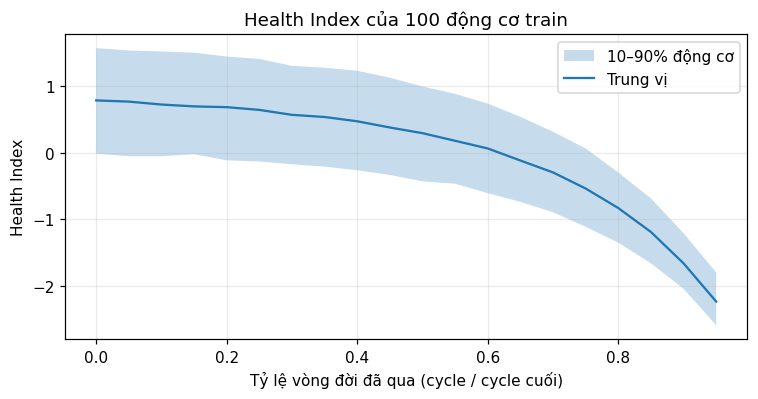

In [3]:
life = health_index.groupby("engine_id")["cycle"].transform("max")
hi = health_index.assign(life_fraction=health_index["cycle"] / life)
hi["bin"] = (hi["life_fraction"] * 20).clip(upper=19.999).astype(int) / 20
band = hi.groupby("bin")["health_index"].quantile([0.1, 0.5, 0.9]).unstack()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(band.index, band[0.1], band[0.9], alpha=0.25, label="10–90% động cơ")
ax.plot(band.index, band[0.5], label="Trung vị")
ax.set(xlabel="Tỷ lệ vòng đời đã qua (cycle / cycle cuối)", ylabel="Health Index", title="Health Index của 100 động cơ train")
ax.legend()
plt.show()

**Nhận xét.** Cả 100 động cơ đều có ρ âm, từ −0.96 đến −0.84, trung vị −0.93. Health Index
giảm nhất quán theo cycle ở mọi động cơ chứ không chỉ ở trung bình. Khi quy về tỷ lệ vòng
đời, đường trung vị đi xuống chậm trong khoảng 60% đầu rồi dốc hẳn ở phần cuối. Điều này
quan trọng cho phần sau: đoạn holdout của ARIMA nằm ở cuối chuỗi, đúng chỗ độ dốc đổi, nên
một mô hình học từ phần đầu dễ dự báo chậm hơn thực tế.

## 2. Sai số ARIMA trên đoạn holdout

Tôi chọn 10 động cơ để dự báo, chia đều theo fold và trải đều theo độ dài vòng đời. Với mỗi
động cơ, 70% đầu chuỗi dùng để fit ARIMA (bậc p, d, q chọn theo AIC), 30% cuối làm holdout.
Ngoài MAE và RMSE, coverage là tỷ lệ điểm holdout rơi vào khoảng dự đoán 95%; nếu khoảng dự
đoán đáng tin, con số này phải gần 0.95.

In [4]:
arima = forecast_metrics.set_index("engine_id").sort_index()
arima[["order", "n_train", "n_holdout", "mae", "rmse", "coverage_95"]]

,order,n_train,n_holdout,mae,rmse,coverage_95
engine_id,,,,,,
24,"(1, 0, 1)",102,45,0.1572,0.1897,0.9556
39,"(0, 1, 1)",89,39,0.8860,1.0788,0.3590
57,"(1, 0, 2)",95,42,0.4346,0.5230,0.5000
67,"(2, 0, 1)",219,94,0.1607,0.2018,0.9362
69,"(1, 0, 1)",253,109,0.4585,0.5645,0.5046
70,"(2, 1, 2)",95,42,1.0372,1.2205,0.2143
83,"(1, 0, 1)",205,88,0.1708,0.2171,0.8750
91,"(1, 0, 1)",94,41,0.4900,0.6422,0.4878
92,"(1, 0, 1)",238,103,0.1631,0.2066,0.8932


In [5]:
arima[["mae", "rmse", "coverage_95"]].mean().round(3)

mae            0.411
rmse           0.503
coverage_95    0.670
dtype: float64

**Nhận xét.** Sai số chia thành hai nhóm rõ. Năm động cơ 24, 67, 83, 92 và 96 có MAE khoảng
0.15–0.17, chưa tới 0.2 độ lệch chuẩn của Health Index, và coverage 0.88–0.97. Năm động cơ
còn lại có MAE từ 0.43 trở lên, nặng nhất là động cơ 70 (MAE 1.04, coverage 0.21) và 39
(MAE 0.89, coverage 0.36). Coverage trung bình chỉ 0.67,
thấp hơn nhiều so với mức danh nghĩa 0.95, nên khoảng dự đoán của ARIMA hẹp quá mức.

## 3. ARIMA có hơn cách dự báo ngây thơ không?

Một mô hình chuỗi thời gian chỉ đáng dùng nếu nó hơn được cách làm đơn giản nhất. Tôi so với
hai baseline dùng cùng điểm cắt: `last_value` giữ nguyên giá trị cuối của đoạn fit, còn
`drift` kéo dài đường thẳng nối điểm đầu và điểm cuối của đoạn fit.

In [6]:
rows = []
for r in arima.itertuples():
    series = health_index[health_index["engine_id"] == r.Index].sort_values("cycle")["health_index"].to_numpy()
    fit, holdout = series[: r.n_train], series[r.n_train : r.n_train + r.n_holdout]
    for name, scores in evaluate_forecast_baselines(fit, holdout).items():
        rows.append({"engine_id": r.Index, "baseline": name, "mae": scores["mae"]})

comparison = pd.DataFrame(rows).pivot(index="engine_id", columns="baseline", values="mae")
comparison["arima"] = arima["mae"]
comparison["arima_best"] = comparison["arima"] < comparison[["last_value", "drift"]].min(axis=1)
comparison.round(4)

baseline,drift,last_value,arima,arima_best
engine_id,,,,
24,0.9198,1.1567,0.1572,True
39,0.7108,0.8701,0.8860,False
57,1.5685,1.6304,0.4346,True
67,0.4567,0.7095,0.1607,True
69,0.5023,0.7813,0.4585,True
70,0.7990,0.9586,1.0372,False
83,1.0064,1.2305,0.1708,True
91,0.3286,0.5289,0.4900,False
92,0.5105,0.6991,0.1631,True


In [7]:
print("ARIMA có MAE thấp nhất ở", comparison["arima_best"].sum(), "/", len(comparison), "động cơ")
comparison[["last_value", "drift", "arima"]].mean().round(3)

ARIMA có MAE thấp nhất ở 7 / 10 động cơ


baseline
last_value    0.948
drift         0.747
arima         0.411
dtype: float64

**Nhận xét.** ARIMA có MAE thấp nhất ở 7/10 động cơ. Tính trung bình, MAE của ARIMA là 0.41,
so với 0.75 của `drift` và 0.95 của `last_value`, tức giảm khoảng 45% so với baseline tốt
hơn. `last_value` luôn kém nhất vì Health Index có xu hướng giảm, nên giữ nguyên giá trị
cuối là sai một cách có hệ thống. Ba động cơ ARIMA thua là 39, 70 và 91; ở cả ba, `drift`
tốt hơn, nghĩa là xu hướng tuyến tính đơn giản bắt được đoạn cuối tốt hơn ARIMA.

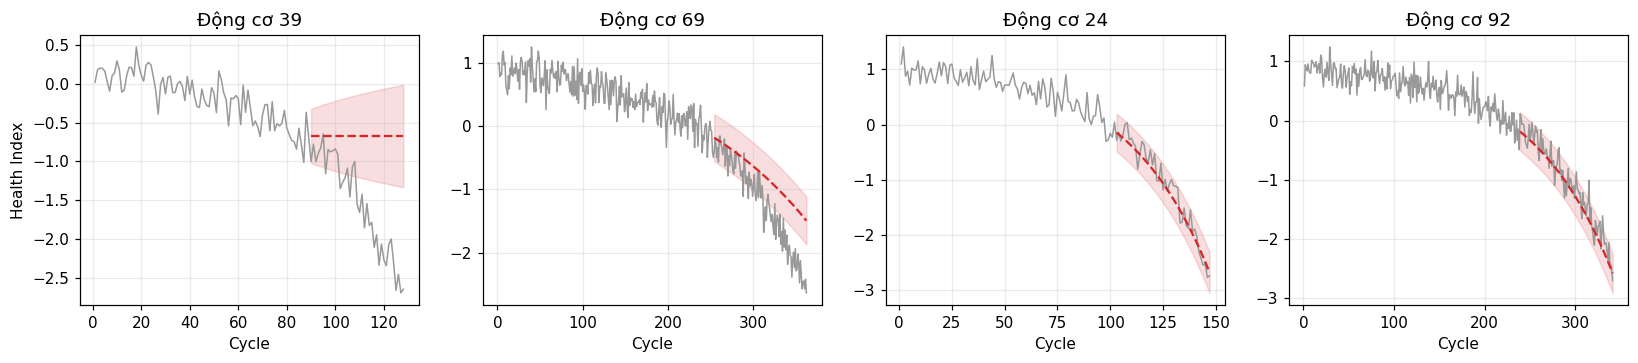

In [8]:
engines = forecast_metrics["engine_id"].tolist()[:4]
fig, axes = plt.subplots(1, len(engines), figsize=(15, 3.4))
for ax, engine_id in zip(axes, engines):
    history = health_index[health_index["engine_id"] == engine_id]
    fc = forecasts[forecasts["engine_id"] == engine_id]
    ax.plot(history["cycle"], history["health_index"], color="0.6", linewidth=1)
    ax.plot(fc["cycle"], fc["health_index_pred"], color="tab:red", linestyle="--")
    ax.fill_between(fc["cycle"], fc["lower_95"], fc["upper_95"], color="tab:red", alpha=0.15)
    ax.set(title=f"Động cơ {engine_id}", xlabel="Cycle")
axes[0].set_ylabel("Health Index")
plt.tight_layout()
plt.show()

**Nhận xét.** Hình động cơ 39 cho thấy rõ vấn đề: dự báo ARIMA gần như đi ngang trong khi
Health Index thật đổ dốc ở đoạn cuối, nên phần lớn điểm holdout rơi ra ngoài khoảng dự đoán.
Đây đúng là tình huống đã thấy ở mục 1, khi độ dốc ở cuối đời lớn hơn hẳn đoạn ARIMA được
học.

## 4. Kiểm tra chuỗi fit và residual

Hai kiểm định đi kèm mỗi mô hình. ADF test kiểm tra chuỗi có dừng hay không; p-value lớn
nghĩa là không bác bỏ giả thuyết có unit root, tức chuỗi có xu hướng. Ljung–Box test trên
residual kiểm tra residual còn tự tương quan không; p-value dưới 0.05 nghĩa là mô hình chưa
nắm hết cấu trúc của chuỗi.

In [9]:
diag = diagnostics.set_index("engine_id").sort_index()[["order", "adf_pvalue", "ljung_box_pvalue", "fit_converged"]]
diag["autocorrelated_5pct"] = diag["ljung_box_pvalue"] < 0.05
diag

,order,adf_pvalue,ljung_box_pvalue,fit_converged,autocorrelated_5pct
engine_id,,,,,
24,"(1, 0, 1)",0.9990,0.0956,True,False
39,"(0, 1, 1)",0.8606,0.8144,True,False
57,"(1, 0, 2)",0.9966,0.5112,True,False
67,"(2, 0, 1)",0.9836,0.7493,True,False
69,"(1, 0, 1)",0.9917,0.0313,True,True
70,"(2, 1, 2)",0.9811,0.0269,True,True
83,"(1, 0, 1)",0.9985,0.4331,True,False
91,"(1, 0, 1)",0.9968,1.0000,True,False
92,"(1, 0, 1)",0.9989,0.4386,True,False


**Nhận xét.** ADF p-value của cả 10 chuỗi đều trên 0.86, nên không chuỗi nào dừng, khớp với
xu hướng giảm đã thấy. Mọi mô hình đều hội tụ. Residual của động cơ 69 (p = 0.031) và 70
(p = 0.027) còn tự tương quan ở mức 5%; động cơ 70 cũng là động cơ có sai số dự báo lớn nhất.

## Tóm tắt

Health Index giảm đều theo cycle ở cả 100 động cơ train và dốc mạnh ở khoảng 40% cuối vòng
đời. ARIMA dự báo chỉ số này tốt hơn hai baseline ngây thơ ở 7/10 động cơ, MAE trung bình
0.41 so với 0.75 của `drift`. Điểm yếu là khoảng dự đoán 95% quá hẹp, coverage trung bình
chỉ 0.67, và ARIMA hụt ở những động cơ mà đoạn cuối đổ dốc nhanh. Dự báo Health Index ở đây
không phải dự đoán RUL và không được dùng để lập lịch bảo trì.